# Deep Retention — Construcción y entrenamiento de la red neuronal

Este notebook consume los artefactos generados por `02_preprocesamiento.ipynb` y entrena el primer perceptrón multicapa (MLP) para estimar la probabilidad de abandono.

No carga el CSV original, no limpia datos, no divide registros y no ajusta escaladores o codificadores. Tampoco abre `test.npz`: el conjunto de prueba permanece reservado para la evaluación definitiva.

## 1. Entorno y reproducibilidad

Se fijan semillas para NumPy y TensorFlow. La arquitectura y los hiperparámetros se mantienen sin cambios respecto al experimento anterior.

In [1]:
import json
import os
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import tensorflow as tf
from IPython.display import display
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.utils.class_weight import compute_class_weight

RANDOM_STATE = 42
SCHEMA_VERSION = "1.0"
MAX_EPOCHS = 100
BATCH_SIZE = 32

np.random.seed(RANDOM_STATE)
tf.keras.utils.set_random_seed(RANDOM_STATE)
try:
    tf.config.experimental.enable_op_determinism()
except Exception as error:
    print(f"Determinismo estricto no disponible: {error}")

print(f"TensorFlow: {tf.__version__}")
print(f"Keras: {tf.keras.__version__}")
print(f"Scikit-learn: {sklearn.__version__}")
print("Dispositivos:", [device.device_type for device in tf.config.list_physical_devices()])

TensorFlow: 2.21.0
Keras: 3.15.1
Scikit-learn: 1.9.1
Dispositivos: ['CPU']


## 2. Carga de datos procesados

El orden de ejecución reproducible es:

1. Ejecutar `02_preprocesamiento.ipynb` para regenerar conjuntamente matrices, preprocesador y metadatos.
2. Ejecutar este notebook para entrenar con `train.npz` y validar con `validation.npz`.

Si falta un archivo o su contrato no coincide, la ejecución se detiene con un mensaje claro; no se regeneran datos silenciosamente.

In [2]:
PROCESSED_CANDIDATES = [
    Path("data") / "processed",
    Path("..") / "data" / "processed",
]
PROCESSED_DIR = next((path for path in PROCESSED_CANDIDATES if path.is_dir()), None)
if PROCESSED_DIR is None:
    raise FileNotFoundError(
        "No existe data/processed. Ejecute primero notebooks/02_preprocesamiento.ipynb."
    )

TRAIN_PATH = PROCESSED_DIR / "train.npz"
VALIDATION_PATH = PROCESSED_DIR / "validation.npz"
METADATA_PATH = PROCESSED_DIR / "metadata.json"
required_paths = [TRAIN_PATH, VALIDATION_PATH, METADATA_PATH]
missing_paths = [path.as_posix() for path in required_paths if not path.is_file()]
if missing_paths:
    raise FileNotFoundError(
        "Faltan artefactos de preprocesamiento. Ejecute primero "
        f"notebooks/02_preprocesamiento.ipynb. Ausentes: {missing_paths}"
    )

metadata = json.loads(METADATA_PATH.read_text(encoding="utf-8"))

with np.load(TRAIN_PATH, allow_pickle=False) as train_artifact:
    X_train_processed = train_artifact["X"].copy()
    y_train_array = train_artifact["y"].copy()
    train_indices = train_artifact["indices"].copy()
    train_artifact_id = train_artifact["artifact_id"].item()

with np.load(VALIDATION_PATH, allow_pickle=False) as validation_artifact:
    X_val_processed = validation_artifact["X"].copy()
    y_val_array = validation_artifact["y"].copy()
    validation_indices = validation_artifact["indices"].copy()
    validation_artifact_id = validation_artifact["artifact_id"].item()

EXPECTED_TRANSFORMED_FEATURES = [
    "CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "EstimatedSalary",
    "Geography_France", "Geography_Germany", "Geography_Spain",
    "HasCrCard", "IsActiveMember",
]

compatibility_checks = {
    "Versión de esquema compatible": metadata.get("preprocessing_schema_version") == SCHEMA_VERSION,
    "Semilla compatible": metadata.get("split", {}).get("random_state") == RANDOM_STATE,
    "Nueve predictoras registradas": len(metadata.get("features", [])) == 9,
    "Orden de 11 características compatible": metadata.get("transformed_features") == EXPECTED_TRANSFORMED_FEATURES,
    "Dimensión de entrenamiento compatible": X_train_processed.shape == (7000, 11),
    "Dimensión de validación compatible": X_val_processed.shape == (1500, 11),
    "Etiquetas compatibles": y_train_array.shape == (7000,) and y_val_array.shape == (1500,),
    "Matrices float32": X_train_processed.dtype == X_val_processed.dtype == np.float32,
    "Etiquetas float32": y_train_array.dtype == y_val_array.dtype == np.float32,
    "Valores finitos": bool(np.isfinite(X_train_processed).all() and np.isfinite(X_val_processed).all()),
    "Etiquetas binarias": set(np.unique(y_train_array)) <= {0.0, 1.0} and set(np.unique(y_val_array)) <= {0.0, 1.0},
    "Índices sin solapamiento": not set(train_indices) & set(validation_indices),
    "Identificador común": train_artifact_id == validation_artifact_id == metadata.get("artifact_id"),
    "Versión de Scikit-learn compatible": metadata.get("scikit_learn_version") == sklearn.__version__,
}

failed_checks = [name for name, result in compatibility_checks.items() if not result]
if failed_checks:
    raise ValueError(
        "Los artefactos no son compatibles con este entrenamiento. "
        "Ejecute primero notebooks/02_preprocesamiento.ipynb. "
        f"Comprobaciones fallidas: {failed_checks}"
    )

display(pd.DataFrame({
    "comprobación": compatibility_checks.keys(),
    "resultado": compatibility_checks.values(),
}))
print("Directorio procesado:", PROCESSED_DIR.as_posix())
print("Identificador de artefactos:", metadata["artifact_id"])
print("Características:", metadata["transformed_features"])
print("El archivo test.npz no se carga en este notebook.")

,comprobación,resultado
0,Versión de esquema compatible,True
1,Semilla compatible,True
2,Nueve predictoras registradas,True
3,Orden de 11 características compatible,True
4,Dimensión de entrenamiento compatible,True
5,Dimensión de validación compatible,True
6,Etiquetas compatibles,True
7,Matrices float32,True
8,Etiquetas float32,True
9,Valores finitos,True


Directorio procesado: ../data/processed
Identificador de artefactos: 3a2890fbab71e9c8
Características: ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary', 'Geography_France', 'Geography_Germany', 'Geography_Spain', 'HasCrCard', 'IsActiveMember']
El archivo test.npz no se carga en este notebook.


## 3. Ponderación de clases

Los pesos se calculan exclusivamente con `y_train_array` mediante `compute_class_weight(class_weight="balanced")`. La clase minoritaria contribuye más a la pérdida durante el ajuste; no se aplica SMOTE ni se duplican o eliminan clientes.

In [3]:
classes = np.array([0, 1], dtype=int)
training_labels = y_train_array.astype(int)
balanced_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=training_labels,
)
class_weights = {
    int(class_label): float(weight)
    for class_label, weight in zip(classes, balanced_weights)
}

class_counts = pd.Series(training_labels).value_counts().sort_index()
class_weight_summary = pd.DataFrame({
    "clase": classes,
    "significado": ["Permaneció", "Abandonó"],
    "clientes_entrenamiento": [int(class_counts.loc[class_label]) for class_label in classes],
    "porcentaje_entrenamiento": [
        class_counts.loc[class_label] / len(training_labels) * 100
        for class_label in classes
    ],
    "peso": [class_weights[int(class_label)] for class_label in classes],
})
display(class_weight_summary)
print("Diccionario para Keras:", class_weights)

,clase,significado,clientes_entrenamiento,porcentaje_entrenamiento,peso
0,0,Permaneció,5574,79.628571,0.627915
1,1,Abandonó,1426,20.371429,2.454418


Diccionario para Keras: {0: 0.6279153211338356, 1: 2.4544179523141656}


## 4. Arquitectura del MLP

La dimensión de entrada se obtiene dinámicamente de `X_train_processed`. Se conserva exactamente la arquitectura del experimento anterior.

In [4]:
input_dimension = X_train_processed.shape[1]

model = tf.keras.Sequential(
    [
        tf.keras.layers.Input(shape=(input_dimension,), name="input"),
        tf.keras.layers.Dense(128, activation="relu", name="dense_128"),
        tf.keras.layers.BatchNormalization(name="batch_normalization"),
        tf.keras.layers.Dropout(0.25, name="dropout_025"),
        tf.keras.layers.Dense(64, activation="relu", name="dense_64"),
        tf.keras.layers.Dropout(0.15, name="dropout_015"),
        tf.keras.layers.Dense(1, activation="sigmoid", name="output"),
    ],
    name="deep_retention_mlp",
)

model.summary()
print(f"Dimensión de entrada: {input_dimension}")
print(f"Parámetros totales: {model.count_params():,}")

Model: "deep_retention_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_128 (Dense)               │ (None, 128)            │         1,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_025 (Dropout)           │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_64 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_015 (Dropout)           │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,369 (40.50 KB)

 Trainable params: 10,113 (39.50 KB)

 Non-trainable params: 256 (1.00 KB)

Dimensión de entrada: 11
Parámetros totales: 10,369


**Decisiones de arquitectura.** ReLU aporta no linealidad; `BatchNormalization` estabiliza activaciones; Dropout limita el sobreajuste; y Sigmoid produce una salida entre 0 y 1. Esa salida requiere evaluación de calibración posterior antes de utilizarse en decisiones financieras.

## 5. Compilación y Early Stopping

Se mantienen Adam, Binary Crossentropy, Binary Accuracy, ROC-AUC y PR-AUC. Early Stopping observa `val_loss`, utiliza paciencia 12 y restaura los mejores pesos.

In [5]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss=tf.keras.losses.BinaryCrossentropy(),
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.AUC(name="roc_auc", curve="ROC"),
        tf.keras.metrics.AUC(name="pr_auc", curve="PR"),
    ],
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=12,
    restore_best_weights=True,
)

print("Optimizador: Adam")
print("Pérdida: BinaryCrossentropy")
print("Monitor:", early_stopping.monitor)
print("Paciencia:", early_stopping.patience)
print("Restaurar mejores pesos:", early_stopping.restore_best_weights)

Optimizador: Adam
Pérdida: BinaryCrossentropy
Monitor: val_loss
Paciencia: 12
Restaurar mejores pesos: True


## 6. Entrenamiento

El modelo recibe únicamente entrenamiento y validación. `class_weight` se aplica solo al entrenamiento; validación conserva su distribución original. `test.npz` permanece fuera del proceso.

In [6]:
history = model.fit(
    X_train_processed,
    y_train_array,
    validation_data=(X_val_processed, y_val_array),
    epochs=MAX_EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weights,
    callbacks=[early_stopping],
    verbose=2,
)

history_df = pd.DataFrame(history.history)
epochs_executed = len(history_df)
best_epoch = int(history_df["val_loss"].idxmin() + 1)
best_val_loss = float(history_df["val_loss"].min())
early_stopping_applied = epochs_executed < MAX_EPOCHS

training_run_summary = pd.DataFrame({
    "configuración": [
        "Épocas máximas", "Épocas ejecutadas", "Mejor época por val_loss",
        "Mejor val_loss", "Batch size", "Early Stopping detuvo antes del máximo",
    ],
    "valor": [
        MAX_EPOCHS, epochs_executed, best_epoch,
        best_val_loss, BATCH_SIZE, early_stopping_applied,
    ],
})
display(training_run_summary)

Epoch 1/100
219/219 - 3s - 12ms/step - accuracy: 0.6806 - loss: 0.6170 - pr_auc: 0.4485 - roc_auc: 0.7401 - val_accuracy: 0.7467 - val_loss: 0.5501 - val_pr_auc: 0.6299 - val_roc_auc: 0.8414
Epoch 2/100
219/219 - 1s - 3ms/step - accuracy: 0.7297 - loss: 0.5452 - pr_auc: 0.5645 - roc_auc: 0.7987 - val_accuracy: 0.7807 - val_loss: 0.4699 - val_pr_auc: 0.6723 - val_roc_auc: 0.8586
Epoch 3/100
219/219 - 1s - 3ms/step - accuracy: 0.7529 - loss: 0.5121 - pr_auc: 0.6098 - roc_auc: 0.8256 - val_accuracy: 0.7860 - val_loss: 0.4594 - val_pr_auc: 0.6794 - val_roc_auc: 0.8611
Epoch 4/100
219/219 - 1s - 3ms/step - accuracy: 0.7641 - loss: 0.5007 - pr_auc: 0.6265 - roc_auc: 0.8334 - val_accuracy: 0.7707 - val_loss: 0.4588 - val_pr_auc: 0.6982 - val_roc_auc: 0.8689
Epoch 5/100
219/219 - 1s - 3ms/step - accuracy: 0.7643 - loss: 0.4975 - pr_auc: 0.6295 - roc_auc: 0.8372 - val_accuracy: 0.7887 - val_loss: 0.4448 - val_pr_auc: 0.7037 - val_roc_auc: 0.8717
Epoch 6/100
219/219 - 1s - 3ms/step - accuracy: 0

,configuración,valor
0,Épocas máximas,100
1,Épocas ejecutadas,39
2,Mejor época por val_loss,27
3,Mejor val_loss,0.418367
4,Batch size,32
5,Early Stopping detuvo antes del máximo,True


In [7]:
training_evaluation = model.evaluate(
    X_train_processed,
    y_train_array,
    verbose=0,
    return_dict=True,
)
validation_evaluation = model.evaluate(
    X_val_processed,
    y_val_array,
    verbose=0,
    return_dict=True,
)

evaluation_comparison = pd.DataFrame(
    [training_evaluation, validation_evaluation],
    index=["Entrenamiento", "Validación"],
)
display(evaluation_comparison.round(4))

,accuracy,loss,pr_auc,roc_auc
Entrenamiento,0.8266,0.3873,0.7432,0.8972
Validación,0.8040,0.4184,0.7093,0.8669


## 7. Curvas de entrenamiento

Se comparan pérdida y precisión entre entrenamiento y validación. La precisión no se interpreta de manera aislada debido al desbalance.

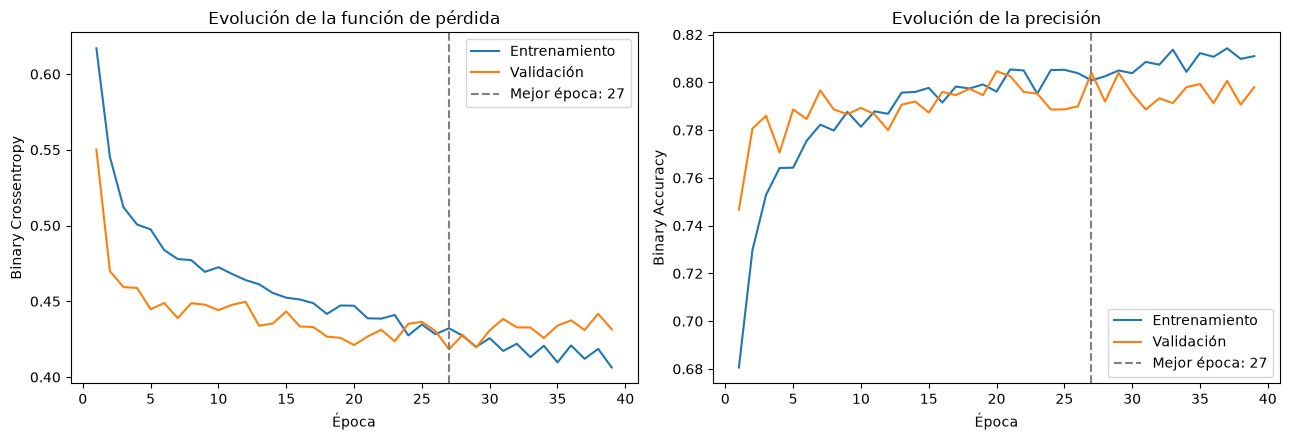

In [8]:
epochs_axis = np.arange(1, epochs_executed + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(epochs_axis, history_df["loss"], label="Entrenamiento")
axes[0].plot(epochs_axis, history_df["val_loss"], label="Validación")
axes[0].axvline(best_epoch, color="gray", linestyle="--", label=f"Mejor época: {best_epoch}")
axes[0].set_title("Evolución de la función de pérdida")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Binary Crossentropy")
axes[0].legend()

axes[1].plot(epochs_axis, history_df["accuracy"], label="Entrenamiento")
axes[1].plot(epochs_axis, history_df["val_accuracy"], label="Validación")
axes[1].axvline(best_epoch, color="gray", linestyle="--", label=f"Mejor época: {best_epoch}")
axes[1].set_title("Evolución de la precisión")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Binary Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

### Interpretación de las curvas

La pérdida disminuye durante las primeras épocas y alcanza su mejor valor de validación en la época 27 (`val_loss = 0,4184`). Después, la pérdida de entrenamiento continúa descendiendo mientras `val_loss` fluctúa sin una mejora sostenida. La diferencia entre ROC-AUC de entrenamiento (0,8972) y validación (0,8669) sugiere sobreajuste leve.

Early Stopping detuvo el ajuste en la época 39, después de 12 épocas sin mejorar, y restauró los pesos de la época 27. Las curvas confirman que el modelo aprende; la accuracy se interpreta con cautela por el desbalance y la ponderación de clases.

## 8. Evaluación inicial en validación

ROC-AUC mide ordenamiento; Average Precision resume la curva Precision-Recall; y Brier Score mide error cuadrático de las probabilidades. No se aplica calibración y no se genera ninguna métrica sobre prueba.

In [9]:
validation_probabilities = model.predict(X_val_processed, verbose=0).reshape(-1)

probabilities_are_finite = bool(np.isfinite(validation_probabilities).all())
probabilities_in_range = bool(
    ((validation_probabilities >= 0) & (validation_probabilities <= 1)).all()
)
if not probabilities_are_finite or not probabilities_in_range:
    raise ValueError("Las probabilidades de validación no son finitas o están fuera de [0, 1].")

validation_roc_auc = float(roc_auc_score(y_val_array, validation_probabilities))
validation_average_precision = float(
    average_precision_score(y_val_array, validation_probabilities)
)
validation_brier_score = float(
    brier_score_loss(y_val_array, validation_probabilities)
)

prediction_checks = pd.DataFrame({
    "comprobación": [
        "Cantidad de probabilidades", "Probabilidades finitas",
        "Probabilidades dentro de [0, 1]", "Probabilidad mínima",
        "Probabilidad máxima",
    ],
    "resultado": [
        len(validation_probabilities), probabilities_are_finite,
        probabilities_in_range, validation_probabilities.min(),
        validation_probabilities.max(),
    ],
})
display(prediction_checks)

validation_metrics = pd.DataFrame({
    "métrica": ["ROC-AUC", "Average Precision", "Brier Score"],
    "validación": [
        validation_roc_auc,
        validation_average_precision,
        validation_brier_score,
    ],
})
display(validation_metrics.round(4))

,comprobación,resultado
0,Cantidad de probabilidades,1500
1,Probabilidades finitas,True
2,"Probabilidades dentro de [0, 1]",True
3,Probabilidad mínima,0.000411
4,Probabilidad máxima,1.0


,métrica,validación
0,ROC-AUC,0.8669
1,Average Precision,0.7099
2,Brier Score,0.1354


## 9. Resultados y conclusiones

- **Origen de los datos:** `train.npz` y `validation.npz`, identificados por `3a2890fbab71e9c8` y generados conjuntamente por `02_preprocesamiento.ipynb`. Las matrices e índices coinciden byte por byte con el flujo anterior.
- **Arquitectura:** 11 entradas; `Dense(128, ReLU)`; Batch Normalization; Dropout 0,25; `Dense(64, ReLU)`; Dropout 0,15; y `Dense(1, Sigmoid)`.
- **Parámetros:** 10.369 totales, 10.113 entrenables y 256 no entrenables.
- **Pesos de clase:** clase 0 = 0,6279 y clase 1 = 2,4544, calculados exclusivamente con las 5.574 permanencias y 1.426 abandonos de entrenamiento.
- **Configuración:** Adam, Binary Crossentropy, máximo de 100 épocas, lotes de 32 y Early Stopping sobre `val_loss` con paciencia 12.
- **Entrenamiento:** 39 épocas ejecutadas; mejor época 27, con `val_loss = 0,4184`.
- **Validación:** accuracy 0,8040, ROC-AUC 0,8669, PR-AUC de Keras 0,7093, Average Precision 0,7099 y Brier Score 0,1354.
- **Curvas:** aprendizaje claro al inicio y sobreajuste leve después de la mejor época, limitado por Early Stopping.

No hubo diferencias numéricas respecto al experimento anterior: las matrices, épocas, mejor época y métricas se reprodujeron exactamente en este entorno. Esto demuestra que el notebook 3 puede entrenar sin repetir limpieza, división o ajuste de transformadores.

El conjunto de prueba no se cargó ni se utilizó. Este sigue siendo un primer modelo académico evaluado solo con validación; permanecen pendientes la calibración, la evaluación final aislada y la exportación definitiva del MLP. No se infiere idoneidad para producción bancaria.